In [35]:
print("Hello World")

Hello World


In [36]:
import tensorflow as tf

In [37]:
from tensorflow.keras.applications import DenseNet121
model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

In [38]:
model.trainable = False

In [39]:
from tensorflow.keras.layers import GlobalAveragePooling2D,Dense


In [40]:
x = GlobalAveragePooling2D()(model.output)
output = Dense(4,activation="softmax")(x)

In [41]:
MODEL = tf.keras.Model(inputs=model.input,outputs=output)

In [42]:
MODEL.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=['accuracy']
)

In [43]:
from tensorflow.keras.applications.densenet import preprocess_input

image_size=(224,224)
batch_size=32

In [44]:
train = tf.keras.utils.image_dataset_from_directory(
    './data/stage1_balanced/train',
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=True,
    seed=42
)

Found 4849 files belonging to 4 classes.


In [45]:
valid = tf.keras.utils.image_dataset_from_directory(
    './data/stage1_balanced/val',
    image_size=image_size,
    batch_size=batch_size,
    shuffle=False,
    label_mode="categorical"
)

Found 1614 files belonging to 4 classes.


In [46]:
test = tf.keras.utils.image_dataset_from_directory(
    './data/stage1_balanced/test',
    image_size=image_size,
    batch_size=batch_size,
    shuffle=False,
    label_mode="categorical"
)

Found 1621 files belonging to 4 classes.


In [47]:
print("Classes:", train.class_names)


Classes: ['Corona Virus Disease', 'Normal', 'Pneumonia', 'Tuberculosis']


In [48]:
AUTOTUNE = tf.data.AUTOTUNE
def preprocess(image,label):
    images = tf.cast(image, tf.float32)
    images = preprocess_input(images)
    return images, label

In [49]:
train = train.map(preprocess,num_parallel_calls=AUTOTUNE)
valid = valid.map(preprocess,num_parallel_calls=AUTOTUNE)
test = test.map(preprocess,num_parallel_calls=AUTOTUNE)

In [50]:
train = train.prefetch(AUTOTUNE)
valid = valid.prefetch(AUTOTUNE)
test = test.prefetch(AUTOTUNE)

In [51]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7
    )
]

In [52]:
history = MODEL.fit(
    train,
    validation_data=valid,
    callbacks=callbacks,
    verbose=1,
    epochs=200
)

Epoch 1/200


c:\Users\smitp\.conda\envs\Medical\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


152/152 ━━━━━━━━━━━━━━━━━━━━ 124s 764ms/step - accuracy: 0.4191 - loss: 1.3090 - val_accuracy: 0.5774 - val_loss: 1.0299 - learning_rate: 1.0000e-04
Epoch 2/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 109s 718ms/step - accuracy: 0.6874 - loss: 0.8642 - val_accuracy: 0.7528 - val_loss: 0.7410 - learning_rate: 1.0000e-04
Epoch 3/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 111s 729ms/step - accuracy: 0.8064 - loss: 0.6453 - val_accuracy: 0.8290 - val_loss: 0.5907 - learning_rate: 1.0000e-04
Epoch 4/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 112s 737ms/step - accuracy: 0.8521 - loss: 0.5221 - val_accuracy: 0.8618 - val_loss: 0.5012 - learning_rate: 1.0000e-04
Epoch 5/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 111s 725ms/step - accuracy: 0.8773 - loss: 0.4463 - val_accuracy: 0.8848 - val_loss: 0.4410 - learning_rate: 1.0000e-04
Epoch 6/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 108s 708ms/step - accuracy: 0.8901 - loss: 0.3926 - val_accuracy: 0.8934 - val_loss: 0.3986 - learning_rate: 1.0000e-04
Epoch 7/200
152/152 ━━━━━━━━━━━━━━━━━━━━ 109s 

In [53]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test:
    predictions = MODEL.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("y_true:", y_true.shape)
print("y_pred:", y_pred.shape)

y_true: (1621,)
y_pred: (1621,)


In [54]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nMacro F1:",
    f1_score(y_true, y_pred, average="macro", zero_division=0))

print("Weighted F1:",
    f1_score(y_true, y_pred, average="weighted", zero_division=0))

Accuracy: 0.9648365206662554

Classification Report:
              precision    recall  f1-score   support

           0     0.9777    0.9705    0.9741       407
           1     0.9338    0.9777    0.9553       404
           2     0.9714    0.9279    0.9491       402
           3     0.9780    0.9828    0.9804       408

    accuracy                         0.9648      1621
   macro avg     0.9652    0.9647    0.9647      1621
weighted avg     0.9653    0.9648    0.9648      1621


Confusion Matrix:
[[395   1   2   9]
 [  0 395   9   0]
 [  2  27 373   0]
 [  7   0   0 401]]

Macro F1: 0.9647288825743837
Weighted F1: 0.9648042775617868


In [55]:
print("MODEL input:", MODEL.input_shape)
print("MODEL output:", MODEL.output_shape)

MODEL input: (None, 224, 224, 3)
MODEL output: (None, 4)


In [56]:
import numpy as np

y_true_val = []
y_pred_val = []

for images, labels in valid:
    preds = MODEL.predict(images, verbose=0)

    y_true_val.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_val.extend(np.argmax(preds, axis=1))

y_true_val = np.array(y_true_val)
y_pred_val = np.array(y_pred_val)

print("Validation accuracy:",
    np.mean(y_true_val == y_pred_val))

print("Validation prediction counts:")
print(np.bincount(y_pred_val, minlength=4))

Validation accuracy: 0.9591078066914498
Validation prediction counts:
[412 411 387 404]


In [57]:
import joblib

In [60]:
joblib.dump(MODEL,'model2.keras')

['model2.keras']

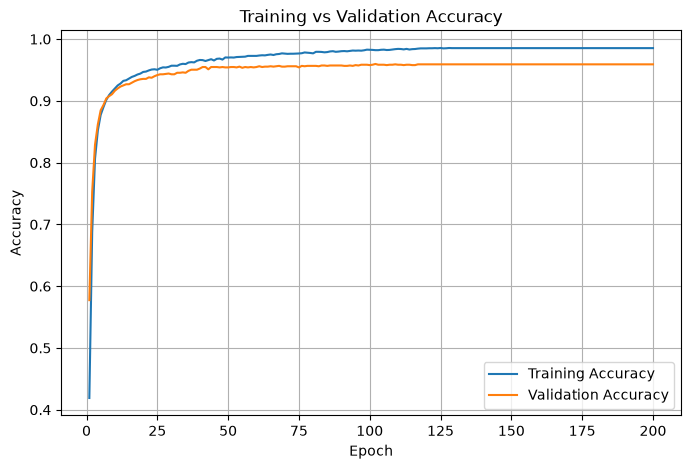

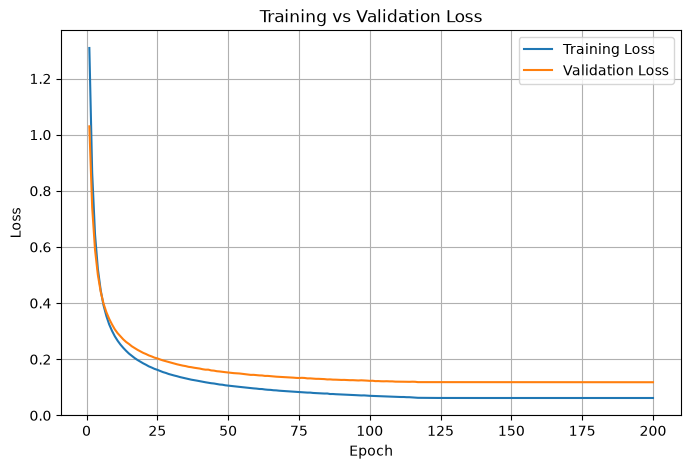

In [59]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# Get history
# -----------------------------
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(acc) + 1)


# =============================
# Accuracy
# =============================
plt.figure(figsize=(8, 5))

plt.plot(epochs, acc, label="Training Accuracy")
plt.plot(epochs, val_acc, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()


# =============================
# Loss
# =============================
plt.figure(figsize=(8, 5))

plt.plot(epochs, loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()